# 02 — Entrenamiento y Evaluación del Modelo

Pipeline completo de ML para detección de fraude bancario:
1. Carga de datos desde DuckDB (capa Gold)
2. Preparación: train/test split + SMOTE (para comparar)
3. Búsqueda de hiperparámetros: RandomizedSearchCV + GridSearchCV
4. Evaluación de cada modelo **con y sin SMOTE**
5. Optimización del umbral de decisión
6. Guardado del modelo final (**XGBoost sin SMOTE, umbral 0.29**) y registro en MLflow


## 1. Instalación e imports

In [1]:
!pip install lightgbm imbalanced-learn xgboost duckdb -q


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import warnings
warnings.filterwarnings('ignore')

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn
import mlflow.xgboost
import mlflow.lightgbm
import joblib

from sklearn.base import clone
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, roc_auc_score,
    confusion_matrix, precision_recall_curve
)
from sklearn.utils import resample
from scipy.stats import randint, uniform

from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


print('Imports OK')

Imports OK


## 2. Carga de datos desde DuckDB

In [3]:
DB_PATH = '../data/fraude.duckdb'

con = duckdb.connect(DB_PATH)
df = con.execute('SELECT * FROM gold_fraud').df()
con.close()

X = df.drop('es_fraude', axis=1)
y = df['es_fraude']

print(f'Features: {X.shape} | Target: {y.shape}')
print(f'Fraudes: {y.sum()} ({y.mean()*100:.2f}%)')

Features: (284807, 30) | Target: (284807,)
Fraudes: 492 (0.17%)


## 3. Preparación de datos

- **Train/test split** con `stratify=y` para mantener la proporción de fraudes en ambos sets
- **SMOTE** solo sobre el train para balancear clases (nunca sobre el test)
- **Muestra del 30%** del train SMOTE para acelerar la búsqueda de hiperparámetros

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print(f'Fraudes en train: {y_train.sum()} | Fraudes en test: {y_test.sum()}')

Train: (227845, 30) | Test: (56962, 30)
Fraudes en train: 394 | Fraudes en test: 98


In [5]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f'Train antes SMOTE : {y_train.value_counts().to_dict()}')
print(f'Train después SMOTE: {pd.Series(y_train_smote).value_counts().to_dict()}')

Train antes SMOTE : {0: 227451, 1: 394}
Train después SMOTE: {0: 227451, 1: 227451}


In [6]:
# Muestra del 30% para búsqueda de hiperparámetros (reduce tiempo de cómputo)
X_train_sample, y_train_sample = resample(
    X_train_smote, y_train_smote,
    n_samples=int(len(X_train_smote) * 0.3),
    random_state=42
)

print(f'Muestra para búsqueda: {X_train_sample.shape}')

Muestra para búsqueda: (136470, 30)


## 4. Definición de modelos

Todos los modelos son **basados en árboles** — robustos a outliers, no necesitan normalización.

In [7]:
MODELOS = {
    'Decision Tree' : DecisionTreeClassifier(random_state=42),
    'Random Forest'  : RandomForestClassifier(random_state=42, n_jobs=-1),
    'XGBoost'        : XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss'),
    'LightGBM'       : LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1)
}

## 5. Búsqueda de hiperparámetros

**Estrategia en dos fases:**
1. `RandomizedSearchCV` — exploración amplia del espacio para encontrar la zona óptima
2. `GridSearchCV` — afinación fina alrededor de esa zona

> **Nota:** Los AUC del cross-validation están inflados porque se evalúan sobre datos SMOTE sintéticos. Los AUC reales se calculan en la sección de evaluación sobre el test set sin SMOTE.

> **Interruptor `BUSCAR_HIPERPARAMETROS`:** la búsqueda tarda bastante. Con `False` se cargan directamente los mejores hiperparámetros ya encontrados (los mismos que salen de la búsqueda, registrados en MLflow) y el notebook entero se ejecuta en pocos minutos. Con `True` se repite la búsqueda completa.


In [8]:
# True  -> repite RandomizedSearchCV + GridSearchCV (tarda mucho)
# False -> usa los mejores hiperparámetros ya encontrados (rápido)
BUSCAR_HIPERPARAMETROS = False

# Espacio amplio para RandomizedSearch
PARAM_RANDOM = {
    'Decision Tree': {
        'max_depth'         : randint(3, 20),
        'min_samples_split' : randint(2, 20),
        'min_samples_leaf'  : randint(1, 10),
        'criterion'         : ['gini', 'entropy']
    },
    'Random Forest': {
        'n_estimators'      : randint(100, 500),
        'max_depth'         : randint(5, 30),
        'min_samples_split' : randint(2, 20),
        'min_samples_leaf'  : randint(1, 10),
        'max_features'      : ['sqrt', 'log2']
    },
    'XGBoost': {
        'n_estimators'      : randint(100, 500),
        'max_depth'         : randint(3, 10),
        'learning_rate'     : uniform(0.01, 0.3),
        'subsample'         : uniform(0.6, 0.4),
        'colsample_bytree'  : uniform(0.6, 0.4),
        'gamma'             : uniform(0, 0.5)
    },
    'LightGBM': {
        'n_estimators'      : randint(100, 500),
        'max_depth'         : randint(3, 10),
        'learning_rate'     : uniform(0.01, 0.3),
        'num_leaves'        : randint(20, 150),
        'subsample'         : uniform(0.6, 0.4),
        'colsample_bytree'  : uniform(0.6, 0.4)
    }
}

def buscar_hiperparametros_random(modelos, param_distributions, X, y, n_iter=20, cv=3):
    """Ejecuta RandomizedSearchCV para cada modelo y devuelve los resultados."""
    resultados = {}
    for nombre, modelo in modelos.items():
        print(f'RandomSearch para {nombre}...')
        rs = RandomizedSearchCV(
            estimator=modelo,
            param_distributions=param_distributions[nombre],
            n_iter=n_iter, cv=cv, scoring='roc_auc',
            n_jobs=-1, random_state=42, verbose=0
        )
        rs.fit(X, y)
        resultados[nombre] = rs
        print(f'  Mejores params: {rs.best_params_}\n')
    return resultados

if BUSCAR_HIPERPARAMETROS:
    resultados_random = buscar_hiperparametros_random(
        MODELOS, PARAM_RANDOM, X_train_sample, y_train_sample
    )
else:
    print('RandomSearch omitido (BUSCAR_HIPERPARAMETROS = False)')

RandomSearch omitido (BUSCAR_HIPERPARAMETROS = False)


In [9]:
# Grid fino alrededor de los mejores parámetros del RandomSearch

PARAM_GRID = {
    'Decision Tree': {
        'max_depth'         : [8, 9, 10],
        'min_samples_leaf'  : [6, 8, 10],
        'min_samples_split' : [14, 16, 18],
        'criterion'         : ['entropy']
    },
    'Random Forest': {
        'max_depth'         : [28],
        'max_features'      : ['sqrt'],
        'min_samples_leaf'  : [6],
        'min_samples_split' : [3],
        'n_estimators'      : [443]
    },
    'XGBoost': {
        'colsample_bytree'  : [0.754],
        'gamma'             : [0.008],
        'learning_rate'     : [0.079],
        'max_depth'         : [6],
        'n_estimators'      : [466],
        'subsample'         : [0.873]
    },
    'LightGBM': {
        'colsample_bytree'  : [0.696],
        'learning_rate'     : [0.215],
        'max_depth'         : [6],
        'n_estimators'      : [363],
        'num_leaves'        : [54],
        'subsample'         : [0.964]
    }
}

def buscar_hiperparametros_grid(modelos, param_grid, X, y, cv=3):
    """Ejecuta GridSearchCV para cada modelo y devuelve los resultados."""
    resultados = {}
    for nombre, modelo in modelos.items():
        print(f'GridSearch para {nombre}...')
        gs = GridSearchCV(
            estimator=modelo,
            param_grid=param_grid[nombre],
            cv=cv, scoring='roc_auc',
            n_jobs=-1, verbose=0
        )
        gs.fit(X, y)
        resultados[nombre] = gs
        print(f'  Mejores params: {gs.best_params_}\n')
    return resultados

# Mejores hiperparámetros obtenidos en la búsqueda (registrados en MLflow)
MEJORES_PARAMS = {
    'Decision Tree': {'criterion': 'entropy', 'max_depth': 9, 'min_samples_leaf': 6, 'min_samples_split': 18},
    'Random Forest': {'max_depth': 28, 'max_features': 'sqrt', 'min_samples_leaf': 6, 'min_samples_split': 3, 'n_estimators': 443},
    'XGBoost'      : {'colsample_bytree': 0.754, 'gamma': 0.008, 'learning_rate': 0.079, 'max_depth': 6, 'n_estimators': 466, 'subsample': 0.873},
    'LightGBM'     : {'colsample_bytree': 0.696, 'learning_rate': 0.215, 'max_depth': 6, 'n_estimators': 363, 'num_leaves': 54, 'subsample': 0.964},
}

if BUSCAR_HIPERPARAMETROS:
    resultados_grid = buscar_hiperparametros_grid(
        MODELOS, PARAM_GRID, X_train_sample, y_train_sample
    )
else:
    # Mismo formato que devuelve GridSearchCV (.best_params_ y .best_estimator_),
    # para que el resto del notebook funcione igual en los dos casos
    from types import SimpleNamespace
    resultados_grid = {
        nombre: SimpleNamespace(
            best_params_=params,
            best_estimator_=clone(MODELOS[nombre]).set_params(**params)
        )
        for nombre, params in MEJORES_PARAMS.items()
    }
    for nombre, params in MEJORES_PARAMS.items():
        print(f'{nombre}: {params}')

Decision Tree: {'criterion': 'entropy', 'max_depth': 9, 'min_samples_leaf': 6, 'min_samples_split': 18}
Random Forest: {'max_depth': 28, 'max_features': 'sqrt', 'min_samples_leaf': 6, 'min_samples_split': 3, 'n_estimators': 443}
XGBoost: {'colsample_bytree': 0.754, 'gamma': 0.008, 'learning_rate': 0.079, 'max_depth': 6, 'n_estimators': 466, 'subsample': 0.873}
LightGBM: {'colsample_bytree': 0.696, 'learning_rate': 0.215, 'max_depth': 6, 'n_estimators': 363, 'num_leaves': 54, 'subsample': 0.964}


## 6. Entrenamiento y evaluación final

Cada modelo se entrena con sus mejores hiperparámetros **dos veces**, para comparar:
- **Con SMOTE:** sobre el train balanceado con datos sintéticos.
- **Sin SMOTE:** sobre el train original, con la proporción real de fraudes (sección 8).

En ambos casos se evalúa sobre el **test real, sin SMOTE**. Se usa `clone()` para que cada versión sea un modelo independiente y no se sobrescriban entre sí.


In [10]:
from sklearn.base import clone


def entrenar_y_evaluar(resultados_grid, X_train, y_train, X_test, y_test):
    """Entrena cada modelo con los mejores params y evalúa sobre el test set."""
    resultados = {}
    for nombre, grid_result in resultados_grid.items():
        # clone() crea un modelo NUEVO con los mismos hiperparámetros.
        # Sin él, best_estimator_ es el mismo objeto en cada llamada y al entrenar
        # sin SMOTE se sobrescribiría el modelo entrenado con SMOTE.
        modelo = clone(grid_result.best_estimator_)
        modelo.fit(X_train, y_train)

        y_pred = modelo.predict(X_test)
        y_prob = modelo.predict_proba(X_test)[:, 1]
        auc    = roc_auc_score(y_test, y_prob)

        resultados[nombre] = {
            'modelo'  : modelo,
            'y_pred'  : y_pred,
            'y_prob'  : y_prob,
            'auc'     : auc,
            'reporte' : classification_report(y_test, y_pred, target_names=['No fraude', 'Fraude'])
        }
        
        print(f'{nombre} — AUC-ROC: {auc:.4f}')
        print(resultados[nombre]['reporte'])
    return resultados


print('=== CON SMOTE ===')
resultados_smote = entrenar_y_evaluar(
    resultados_grid, X_train_smote, y_train_smote, X_test, y_test
)

=== CON SMOTE ===
Decision Tree — AUC-ROC: 0.9205
              precision    recall  f1-score   support

   No fraude       1.00      0.98      0.99     56864
      Fraude       0.08      0.86      0.15        98

    accuracy                           0.98     56962
   macro avg       0.54      0.92      0.57     56962
weighted avg       1.00      0.98      0.99     56962

Random Forest — AUC-ROC: 0.9828
              precision    recall  f1-score   support

   No fraude       1.00      1.00      1.00     56864
      Fraude       0.75      0.88      0.81        98

    accuracy                           1.00     56962
   macro avg       0.88      0.94      0.91     56962
weighted avg       1.00      1.00      1.00     56962

XGBoost — AUC-ROC: 0.9856
              precision    recall  f1-score   support

   No fraude       1.00      1.00      1.00     56864
      Fraude       0.81      0.85      0.83        98

    accuracy                           1.00     56962
   macro avg       0

## 7. Matrices de confusión

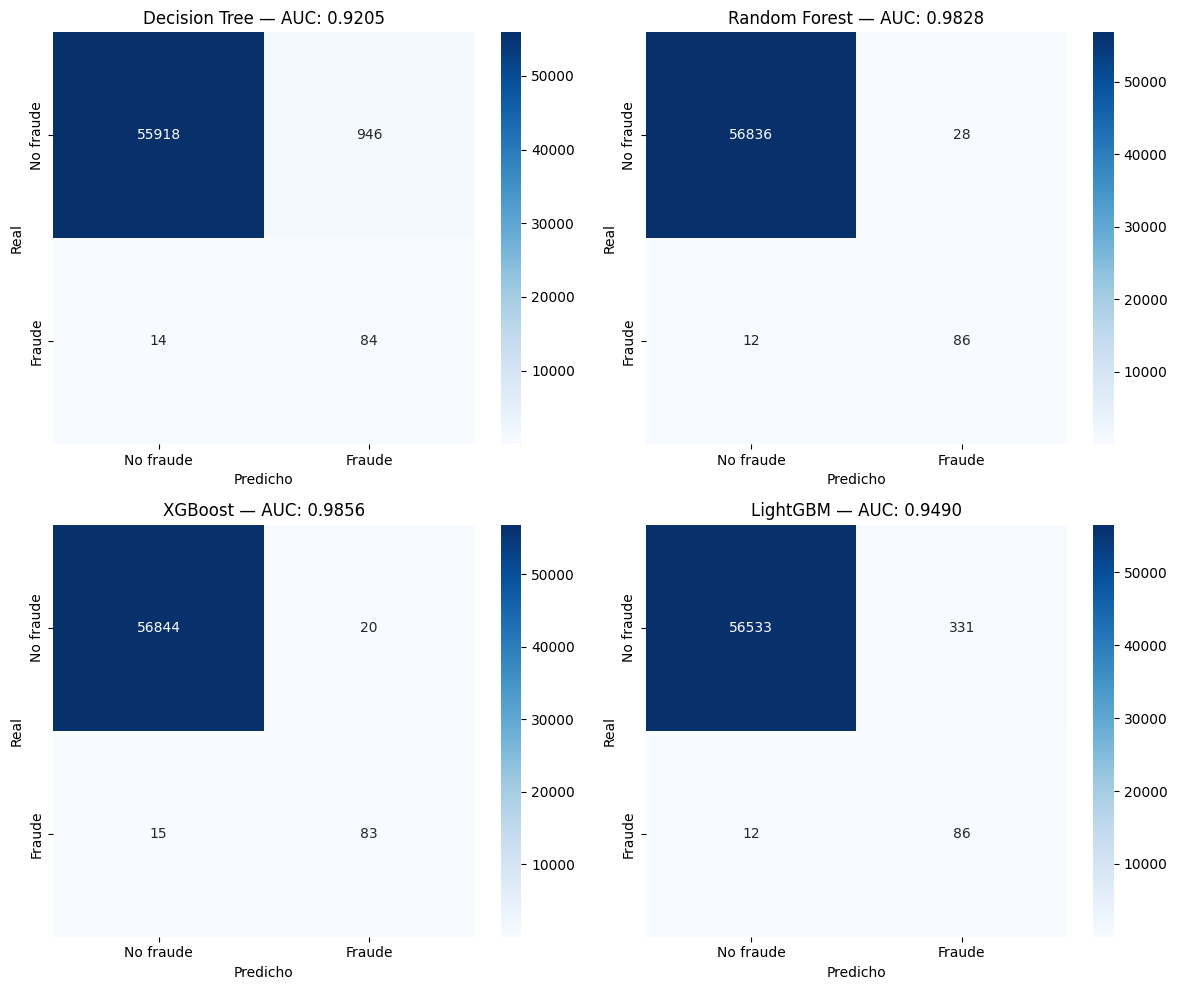

In [11]:
def plot_matrices_confusion(resultados, y_test, cmap='Blues', sufijo=''):
    """Dibuja las matrices de confusión de todos los modelos en un grid 2x2."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.flatten()

    for i, (nombre, resultado) in enumerate(resultados.items()):
        cm = confusion_matrix(y_test, resultado['y_pred'])
        sns.heatmap(
            cm, annot=True, fmt='d', ax=axes[i],
            xticklabels=['No fraude', 'Fraude'],
            yticklabels=['No fraude', 'Fraude'],
            cmap=cmap
        )
        axes[i].set_title(f'{nombre}{sufijo} — AUC: {resultado["auc"]:.4f}')
        axes[i].set_ylabel('Real')
        axes[i].set_xlabel('Predicho')

    plt.tight_layout()
    plt.show()


plot_matrices_confusion(resultados_smote, y_test, cmap='Blues')

## 8. Comparativa con y sin SMOTE

=== SIN SMOTE ===
Decision Tree — AUC-ROC: 0.9270
              precision    recall  f1-score   support

   No fraude       1.00      1.00      1.00     56864
      Fraude       0.84      0.81      0.82        98

    accuracy                           1.00     56962
   macro avg       0.92      0.90      0.91     56962
weighted avg       1.00      1.00      1.00     56962

Random Forest — AUC-ROC: 0.9652
              precision    recall  f1-score   support

   No fraude       1.00      1.00      1.00     56864
      Fraude       0.93      0.82      0.87        98

    accuracy                           1.00     56962
   macro avg       0.96      0.91      0.93     56962
weighted avg       1.00      1.00      1.00     56962

XGBoost — AUC-ROC: 0.9726
              precision    recall  f1-score   support

   No fraude       1.00      1.00      1.00     56864
      Fraude       0.92      0.84      0.88        98

    accuracy                           1.00     56962
   macro avg       0

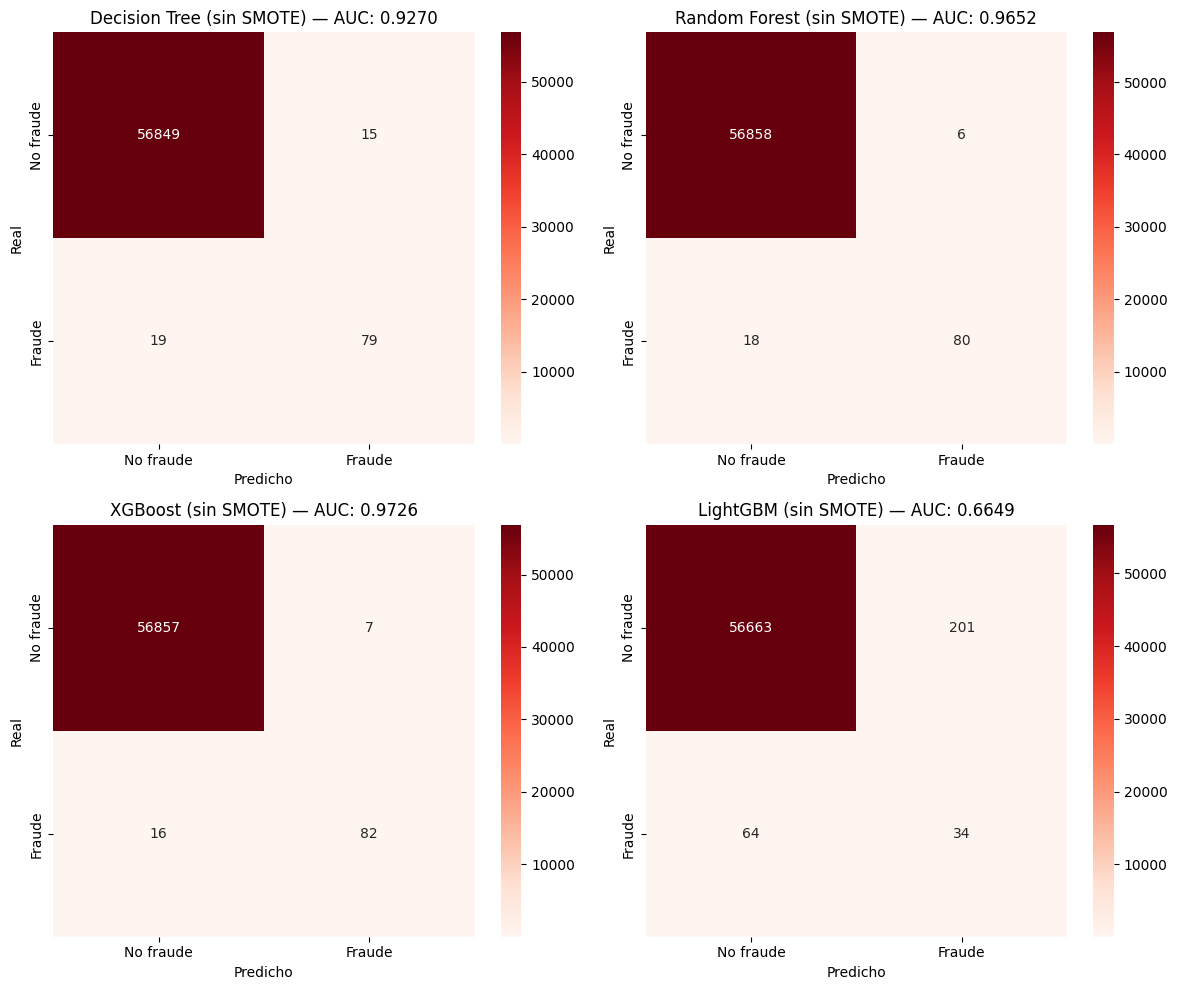

In [12]:
print('=== SIN SMOTE ===')
resultados_sin_smote = entrenar_y_evaluar(
    resultados_grid, X_train, y_train, X_test, y_test
)

plot_matrices_confusion(resultados_sin_smote, y_test, cmap='Reds', sufijo=' (sin SMOTE)')

## 9. Tabla resumen comparativa

In [13]:
def tabla_comparativa(resultados_smote, resultados_sin_smote, y_test):
    """Genera una tabla resumen comparando todos los modelos con y sin SMOTE."""
    filas = []
    for nombre in resultados_smote:
        for label, resultados in [('Con SMOTE', resultados_smote), ('Sin SMOTE', resultados_sin_smote)]:
            r  = resultados[nombre]
            cm = confusion_matrix(y_test, r['y_pred'])
            tn, fp, fn, tp = cm.ravel()
            precision = tp / (tp + fp) if (tp + fp) > 0 else 0
            recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
            f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
            filas.append({
                'Modelo'               : nombre,
                'SMOTE'                : label,
                'AUC-ROC'              : round(r['auc'], 4),
                'Precision Fraude'     : round(precision, 2),
                'Recall Fraude'        : round(recall, 2),
                'F1 Fraude'            : round(f1, 2),
                'Fraudes detectados'   : tp,
                'Falsas alarmas'       : fp,
                'Fraudes no detectados': fn
            })
    return pd.DataFrame(filas).set_index(['Modelo', 'SMOTE'])


tabla = tabla_comparativa(resultados_smote, resultados_sin_smote, y_test)
tabla

AUC-ROC  Precision Fraude  Recall Fraude  F1 Fraude  \
Modelo        SMOTE                                                            
Decision Tree Con SMOTE   0.9205              0.08           0.86       0.15   
              Sin SMOTE   0.9270              0.84           0.81       0.82   
Random Forest Con SMOTE   0.9828              0.75           0.88       0.81   
              Sin SMOTE   0.9652              0.93           0.82       0.87   
XGBoost       Con SMOTE   0.9856              0.81           0.85       0.83   
              Sin SMOTE   0.9726              0.92           0.84       0.88   
LightGBM      Con SMOTE   0.9490              0.21           0.88       0.33   
              Sin SMOTE   0.6649              0.14           0.35       0.20   

                         Fraudes detectados  Falsas alarmas  \
Modelo        SMOTE                                           
Decision Tree Con SMOTE                  84             946   
              Sin SMOTE                  79              15   
Random Forest Con SMOTE                  86              28   
              Sin SMOTE                  80               6   
XGBoost       Con SMOTE                  83              20   
              Sin SMOTE                  82               7   
LightGBM      Con SMOTE                  86             331   
              Sin SMOTE                  34             201   

                         Fraudes no detectados  
Modelo        SMOTE                             
Decision Tree Con SMOTE                     14  
              Sin SMOTE                     19  
Random Forest Con SMOTE                     12  
              Sin SMOTE                     18  
XGBoost       Con SMOTE                     15  
              Sin SMOTE                     16  
LightGBM      Con SMOTE                     12  
              Sin SMOTE                     64

## 10. Optimización del umbral de decisión: XGBoost con y sin SMOTE

El umbral por defecto es 0.5. Ajustándolo podemos mejorar el equilibrio entre precision y recall según las necesidades del negocio.


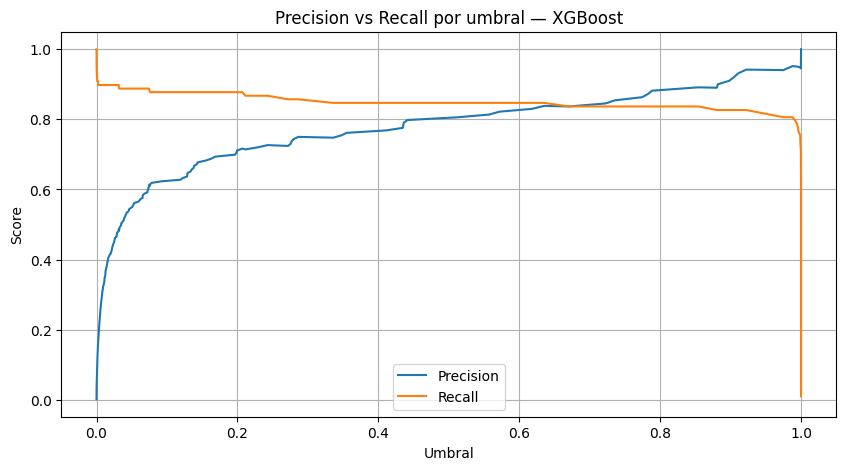

In [14]:
def plot_precision_recall_umbral(y_test, y_prob, nombre_modelo='XGBoost'):
    """Visualiza precision y recall para cada umbral posible."""
    precision, recall, umbrales = precision_recall_curve(y_test, y_prob)

    plt.figure(figsize=(10, 5))
    plt.plot(umbrales, precision[:-1], label='Precision')
    plt.plot(umbrales, recall[:-1],    label='Recall')
    plt.xlabel('Umbral')
    plt.ylabel('Score')
    plt.title(f'Precision vs Recall por umbral — {nombre_modelo}')
    plt.legend()
    plt.grid(True)
    plt.show()


plot_precision_recall_umbral(y_test, resultados_smote['XGBoost']['y_prob'])

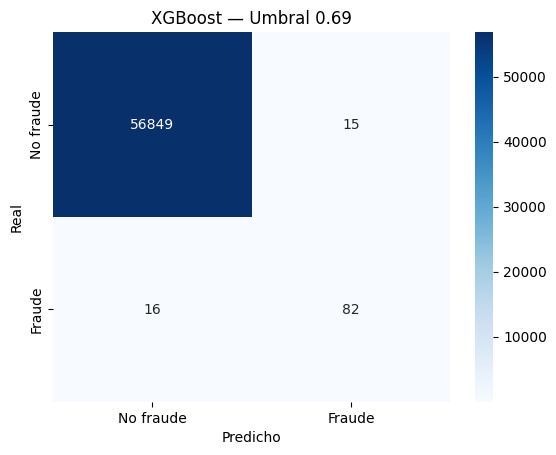

              precision    recall  f1-score   support

   No fraude       1.00      1.00      1.00     56864
      Fraude       0.85      0.84      0.84        98

    accuracy                           1.00     56962
   macro avg       0.92      0.92      0.92     56962
weighted avg       1.00      1.00      1.00     56962



In [15]:
def evaluar_umbral(y_test, y_prob, umbral, nombre_modelo='XGBoost'):
    """Evalúa el modelo con un umbral personalizado y muestra la matriz de confusión."""
    y_pred_umbral = (y_prob >= umbral).astype(int)
    cm = confusion_matrix(y_test, y_pred_umbral)

    sns.heatmap(
        cm, annot=True, fmt='d',
        xticklabels=['No fraude', 'Fraude'],
        yticklabels=['No fraude', 'Fraude'],
        cmap='Blues'
    )
    plt.title(f'{nombre_modelo} — Umbral {umbral}')
    plt.ylabel('Real')
    plt.xlabel('Predicho')
    plt.show()

    print(classification_report(y_test, y_pred_umbral, target_names=['No fraude', 'Fraude']))


evaluar_umbral(y_test, resultados_smote['XGBoost']['y_prob'], umbral=0.69)

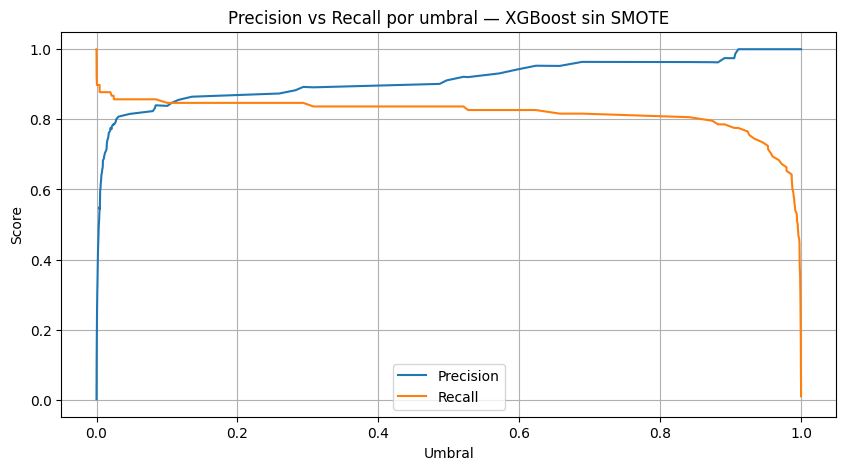

In [16]:
plot_precision_recall_umbral(y_test, resultados_sin_smote['XGBoost']['y_prob'], nombre_modelo='XGBoost sin SMOTE')

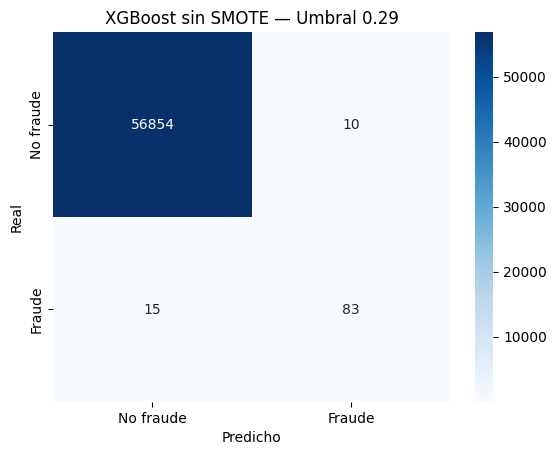

              precision    recall  f1-score   support

   No fraude       1.00      1.00      1.00     56864
      Fraude       0.89      0.85      0.87        98

    accuracy                           1.00     56962
   macro avg       0.95      0.92      0.93     56962
weighted avg       1.00      1.00      1.00     56962



In [17]:
evaluar_umbral(y_test, resultados_sin_smote['XGBoost']['y_prob'], umbral=0.29, nombre_modelo='XGBoost sin SMOTE')

## Decisión final del modelo: impacto de negocio

La elección del modelo y umbral óptimo depende del coste relativo de cada tipo de error:

**Falso Negativo (fraude no detectado):**
- El banco asume la pérdida económica del fraude
- Daño reputacional si el cliente se queja
- Coste típico: importe de la transacción fraudulenta

**Falso Positivo (cliente legítimo bloqueado):**
- El cliente tiene una mala experiencia
- Coste operativo de gestionar la reclamación
- Posible pérdida del cliente a largo plazo
- Coste típico: 10-50€ en atención al cliente

**Regla general:**
- Si el coste de un fraude no detectado >> coste de bloquear un cliente → umbral bajo, más recall (ej. umbral 0.05 con SMOTE)
- Si ambos costes son similares → umbral equilibrado, mejor F1 (ej. XGBoost sin SMOTE umbral 0.29)

En este proyecto usamos **XGBoost sin SMOTE con umbral 0.29** como modelo final por ser el mejor equilibrio entre fraudes detectados y falsas alarmas: detecta 83 de 98 fraudes del test (recall 0.85) con una precisión de 0.89 (F1 0.87).

SMOTE se descarta: mejora ligeramente el recall, pero multiplica las falsas alarmas (21 frente a 7 con XGBoost al umbral por defecto) y en 3 de los 4 modelos empeora el F1.


In [18]:
# Guardamos el modelo FINAL elegido: XGBoost SIN SMOTE (el umbral 0.29 se aplica en src/modelo.py)
import joblib

joblib.dump(resultados_sin_smote['XGBoost']['modelo'], '../src/modelo_xgboost.pkl')
print('Modelo guardado en src/modelo_xgboost.pkl')

Modelo guardado en src/modelo_xgboost.pkl


In [19]:

# Configuramos el experimento
mlflow.set_tracking_uri('sqlite:///../mlflow.db')
mlflow.set_experiment('fraud-detection')
# Registramos cada modelo
for nombre, resultado in resultados_sin_smote.items():
    with mlflow.start_run(run_name=nombre):
        
        # Parámetros del modelo
        mlflow.log_params(resultados_grid[nombre].best_params_)
        
        # Métricas
        cm = confusion_matrix(y_test, resultado['y_pred'])
        tn, fp, fn, tp = cm.ravel()
        
        mlflow.log_metric('auc_roc', resultado['auc'])
        mlflow.log_metric('fraudes_detectados', tp)
        mlflow.log_metric('falsas_alarmas', fp)
        mlflow.log_metric('fraudes_no_detectados', fn)
        mlflow.log_metric('precision_fraude', round(tp/(tp+fp), 4))
        mlflow.log_metric('recall_fraude', round(tp/(tp+fn), 4))
        
        # Guardamos el modelo (DENTRO del run, para que se registren los 4)
        mlflow.log_param('smote', False)
        if nombre == 'XGBoost':
            mlflow.xgboost.log_model(resultado['modelo'], name=nombre)
        elif nombre == 'LightGBM':
            mlflow.lightgbm.log_model(resultado['modelo'], name=nombre)
        else:
            mlflow.sklearn.log_model(resultado['modelo'], name=nombre)
